Chargement et découverte du dataset

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor

from scipy.stats import chi2_contingency, spearmanr

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

In [3]:
ops = pd.read_csv("monitoring_device_operations.csv")

print("Dimensions du dataset :", ops.shape)

print("\nNombre de lignes :", ops.shape[0])
print("Nombre de colonnes :", ops.shape[1])

display(ops.head(10))

Dimensions du dataset : (4994, 11)

Nombre de lignes : 4994
Nombre de colonnes : 11


,device_operation_id,site_code,device_reference,operation_start,operation_end,uptime_pct,acoustic_quality,maintenance_type,fault_code,maintenance_provider,record_status
0,DOP-0000001,KNT-KES,DEV-KNTKES-2,2019-01-01T00:00:00,2019-01-31T23:59:59,92.3,85.9,routine inspection,NaN,ECO-SERVICE-2,closed
1,DOP-0000002,KNT-KES,DEV-KNTKES-2,2019-02-01T00:00:00,2019-02-28T23:59:59,80.6,79.6,routine inspection,NaN,ECO-SERVICE-2,closed
2,DOP-0000003,KNT-KES,DEV-KNTKES-2,2019-03-01T00:00:00,2019-03-31T23:59:59,94.9,82.5,routine inspection,NaN,ECO-SERVICE-2,closed
3,DOP-0000004,KNT-KES,DEV-KNTKES-2,2019-04-01T00:00:00,2019-04-30T23:59:59,94.8,84.8,routine inspection,NaN,ECO-SERVICE-2,closed
4,DOP-0000005,KNT-KES,DEV-KNTKES-2,2019-05-01T00:00:00,2019-05-31T23:59:59,87.7,69.2,routine inspection,NaN,ECO-SERVICE-2,closed
5,DOP-0000006,KNT-KES,DEV-KNTKES-2,2019-06-01T00:00:00,2019-06-30T23:59:59,89.7,72.7,routine inspection,NaN,ECO-SERVICE-2,closed
6,DOP-0000007,KNT-KES,DEV-KNTKES-2,2019-07-01T00:00:00,2019-07-31T23:59:59,98.0,74.0,routine inspection,NaN,ECO-SERVICE-2,closed
7,DOP-0000008,KNT-KES,DEV-KNTKES-2,2019-08-01T00:00:00,2019-08-31T23:59:59,91.4,69.1,routine inspection,NaN,ECO-SERVICE-2,closed
8,DOP-0000009,KNT-KES,DEV-KNTKES-2,2019-09-01T00:00:00,2019-09-30T23:59:59,97.0,68.8,routine inspection,NaN,ECO-SERVICE-2,closed
9,DOP-0000010,KNT-KES,DEV-KNTKES-2,2019-10-01T00:00:00,2019-10-31T23:59:59,98.0,86.3,routine inspection,NaN,ECO-SERVICE-2,closed


Structure et types des variables

In [4]:
print("Informations générales :")
ops.info()

print("\nTypes des variables :")
display(ops.dtypes.to_frame("Type"))

print("\nNombre de valeurs distinctes :")
display(ops.nunique().to_frame("Valeurs uniques"))

Informations générales :
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4994 entries, 0 to 4993
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   device_operation_id   4994 non-null   object 
 1   site_code             4994 non-null   object 
 2   device_reference      4994 non-null   object 
 3   operation_start       4994 non-null   object 
 4   operation_end         4994 non-null   object 
 5   uptime_pct            4994 non-null   object 
 6   acoustic_quality      4994 non-null   float64
 7   maintenance_type      4994 non-null   object 
 8   fault_code            189 non-null    object 
 9   maintenance_provider  4964 non-null   object 
 10  record_status         4994 non-null   object 
dtypes: float64(1), object(10)
memory usage: 429.3+ KB

Types des variables :


,Type
device_operation_id,object
site_code,object
device_reference,object
operation_start,object
operation_end,object
uptime_pct,object
acoustic_quality,float64
maintenance_type,object
fault_code,object
maintenance_provider,object



Nombre de valeurs distinctes :


,Valeurs uniques
device_operation_id,4992
site_code,64
device_reference,64
operation_start,78
operation_end,97
uptime_pct,389
acoustic_quality,458
maintenance_type,5
fault_code,3
maintenance_provider,4


stat

In [5]:
print("Statistiques des variables numériques :")
display(ops.describe())

print("\nStatistiques des variables catégorielles :")
display(ops.describe(include="object"))

Statistiques des variables numériques :


,acoustic_quality
count,4994.000000
mean,78.991270
std,8.505031
min,20.000000
25%,73.900000
50%,79.300000
75%,84.600000
max,100.000000



Statistiques des variables catégorielles :


,device_operation_id,site_code,device_reference,operation_start,operation_end,uptime_pct,maintenance_type,fault_code,maintenance_provider,record_status
count,4994,4994,4994,4994,4994,4994,4994,189,4964,4994
unique,4992,64,64,78,97,389,5,3,4,3
top,DOP-0001226,KNT-CHP,DEV-KNTCHP-3,2023-08-01T00:00:00,2024-05-31T23:59:59,100.0,routine inspection,MICROPHONE_DRIFT,ECO-SERVICE-2,closed
freq,2,79,79,65,65,555,4785,97,1242,4974


distrubution


Distribution de device_operation_id :


,Effectif
device_operation_id,
DOP-0001226,2
DOP-0001391,2
DOP-0003334,1
DOP-0003333,1
DOP-0003332,1
...,...
DOP-0001662,1
DOP-0001661,1
DOP-0001660,1


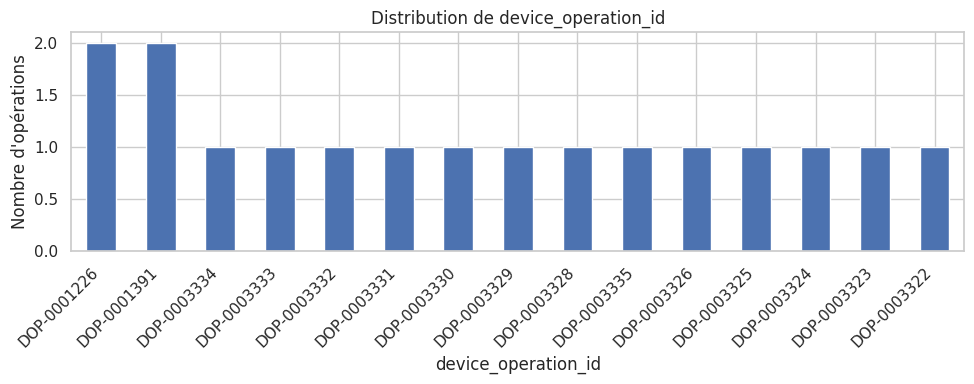


Distribution de site_code :


,Effectif
site_code,
KNT-CHP,79
KNT-WUQ,79
KNT-SEN,78
KNT-KES,78
AVL-VEL,78
...,...
TMB-WST,78
TMB-SXP,78
TMB-WQL,78


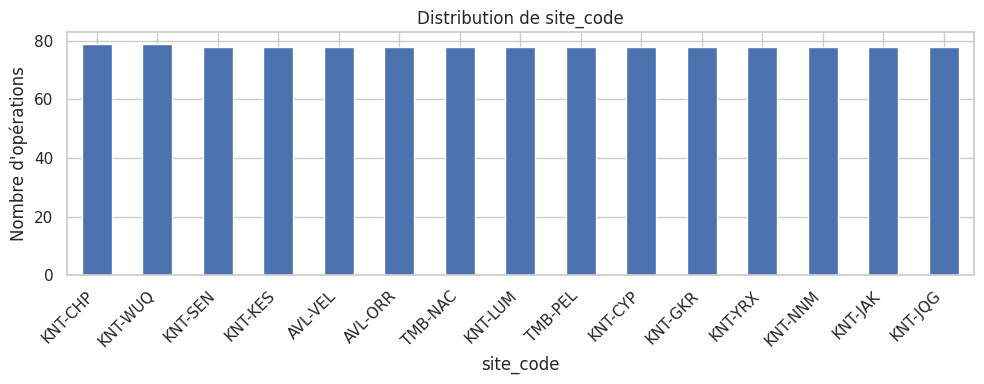


Distribution de device_reference :


,Effectif
device_reference,
DEV-KNTCHP-3,79
DEV-KNTWUQ-2,79
DEV-KNTSEN-1,78
DEV-KNTKES-2,78
DEV-AVLVEL-3,78
...,...
DEV-TMBWST-2,78
DEV-TMBSXP-3,78
DEV-TMBWQL-1,78


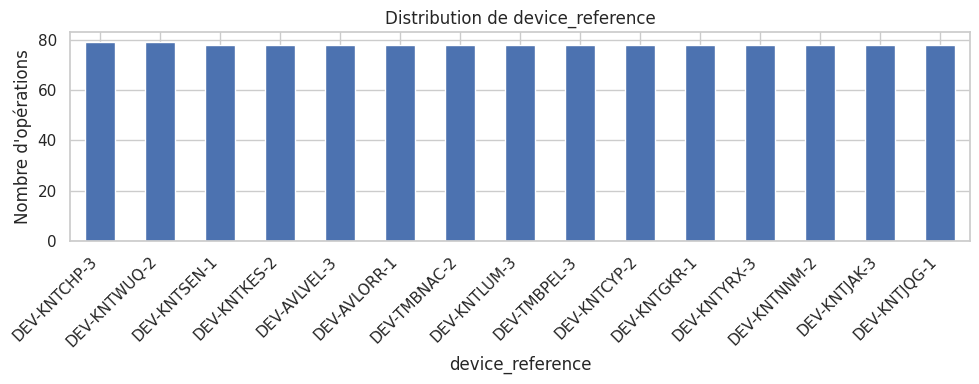


Distribution de operation_start :


,Effectif
operation_start,
2023-08-01T00:00:00,65
2024-05-01T00:00:00,65
2019-03-01T00:00:00,64
2019-04-01T00:00:00,64
2019-01-01T00:00:00,64
...,...
2025-02-01T00:00:00,64
2025-03-01T00:00:00,64
2025-04-01T00:00:00,64


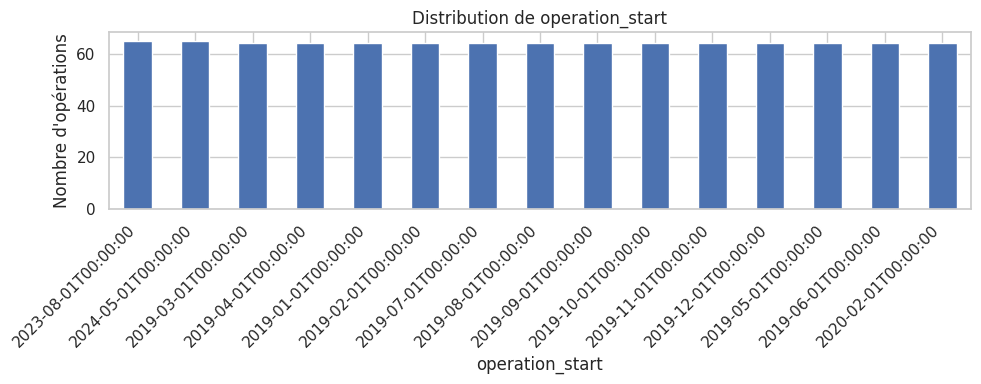


Distribution de operation_end :


,Effectif
operation_end,
2024-05-31T23:59:59,65
2021-08-31T23:59:59,64
2019-05-31T23:59:59,64
2019-07-31T23:59:59,64
2019-06-30T23:59:59,64
...,...
31/01/2019 23:59:59,1
31-Jan-2025 23:59:59,1
30/11/2020 23:59:59,1


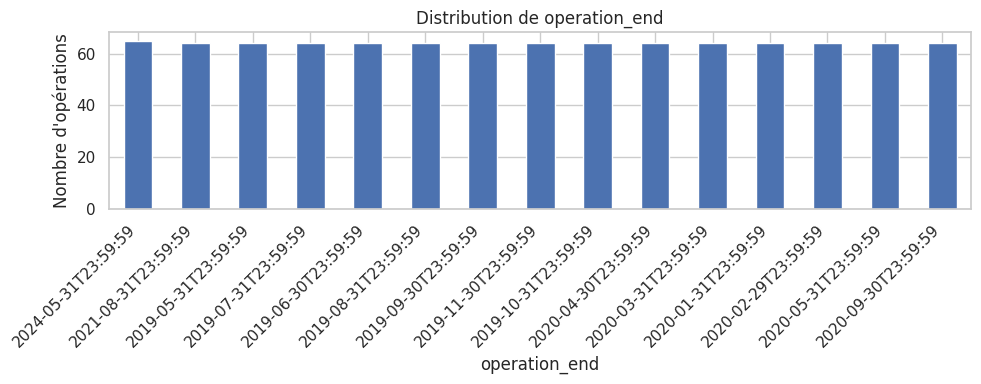


Distribution de uptime_pct :


,Effectif
uptime_pct,
100.0,555
95.3,52
91.4,47
94.2,46
90.5,46
...,...
72.6,1
55.2,1
72.3,1


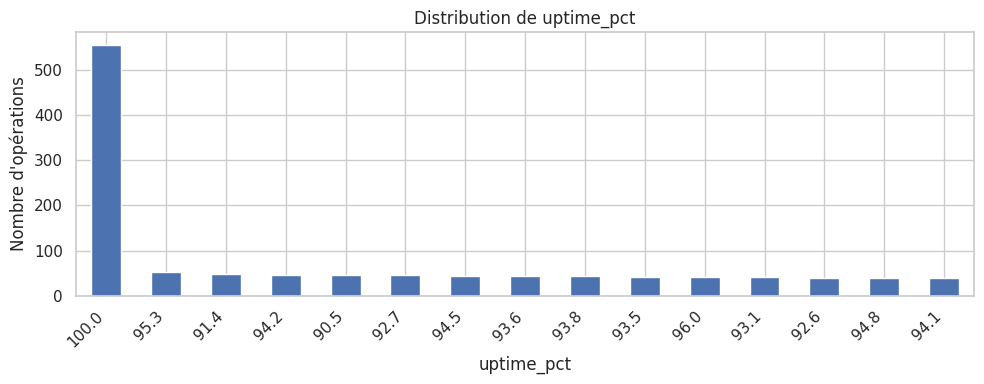


Distribution de maintenance_type :


,Effectif
maintenance_type,
routine inspection,4785
corrective maintenance,137
sensor replacement,52
ROUTINE INSPECTION,12
Routine Inspection,8


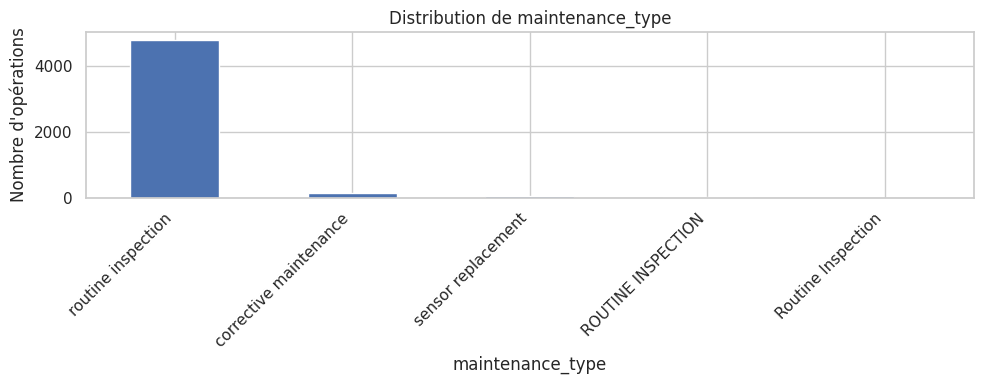


Distribution de fault_code :


,Effectif
fault_code,
NaN,4805
MICROPHONE_DRIFT,97
STORAGE_LIMIT,56
POWER_INTERRUPTION,36


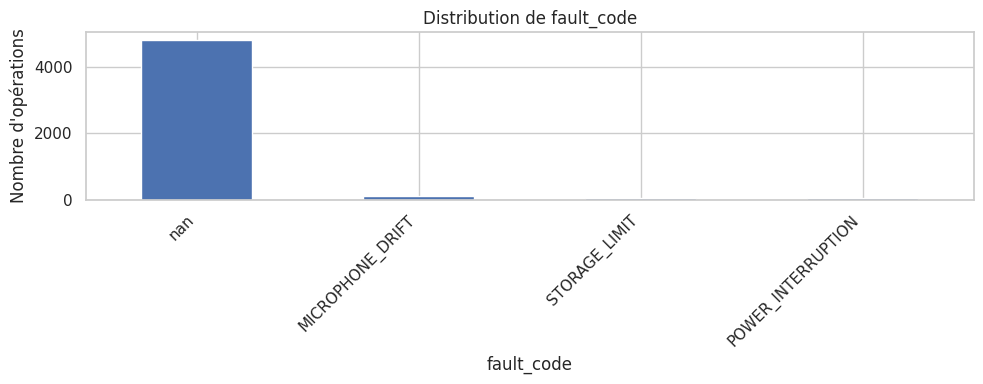


Distribution de maintenance_provider :


,Effectif
maintenance_provider,
ECO-SERVICE-2,1242
ECO-SERVICE-1,1242
ECO-SERVICE-3,1240
ECO-SERVICE-4,1240
NaN,30


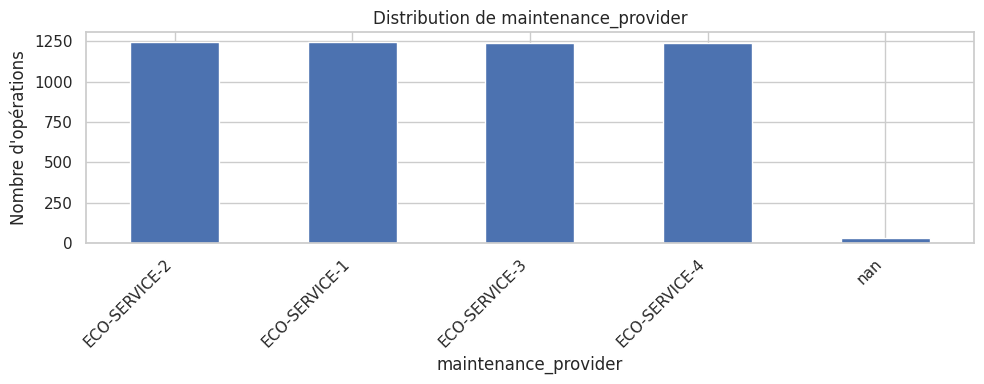


Distribution de record_status :


,Effectif
record_status,
closed,4974
CLOSED,13
Closed,7


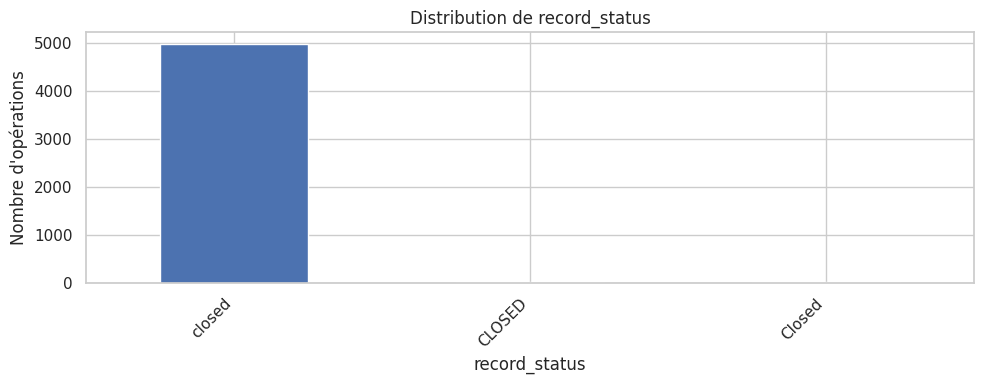

In [6]:
colonnes_cat = ops.select_dtypes(include="object").columns

for col in colonnes_cat:

    print(f"\nDistribution de {col} :")

    display(
        ops[col].value_counts(dropna=False).to_frame("Effectif")
    )

    plt.figure(figsize=(10, 4))

    ops[col].value_counts(dropna=False).head(15).plot(
        kind="bar"
    )

    plt.title(f"Distribution de {col}")
    plt.ylabel("Nombre d'opérations")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

Distribution des var num

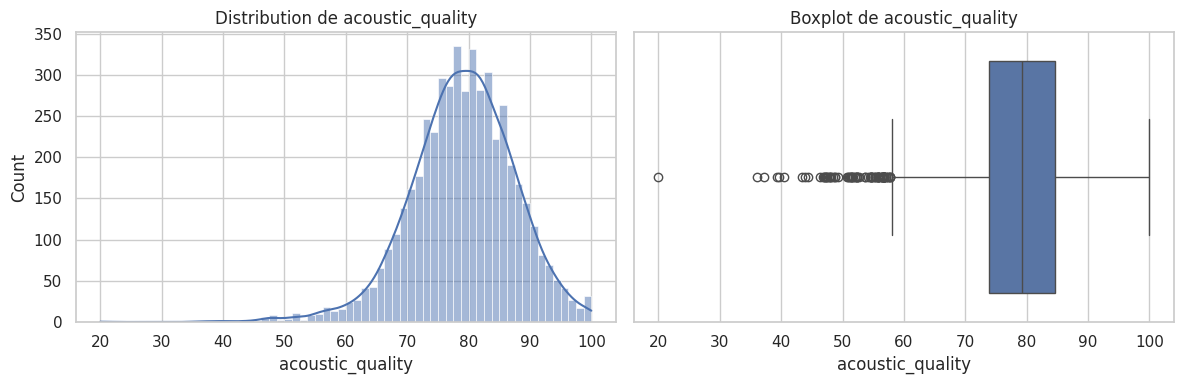

In [7]:
colonnes_num = ops.select_dtypes(include=np.number).columns

for col in colonnes_num:

    valeurs = ops[col].dropna()

    if len(valeurs) == 0:
        continue

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    sns.histplot(valeurs, kde=True, ax=axes[0])
    axes[0].set_title(f"Distribution de {col}")

    sns.boxplot(x=valeurs, ax=axes[1])
    axes[1].set_title(f"Boxplot de {col}")

    plt.tight_layout()
    plt.show()

Analyse des valeurs manquantes

,Valeurs manquantes,Pourcentage (%)
fault_code,4805,96.215459
maintenance_provider,30,0.600721
device_operation_id,0,0.000000
device_reference,0,0.000000
site_code,0,0.000000
operation_start,0,0.000000
operation_end,0,0.000000
acoustic_quality,0,0.000000
uptime_pct,0,0.000000
maintenance_type,0,0.000000


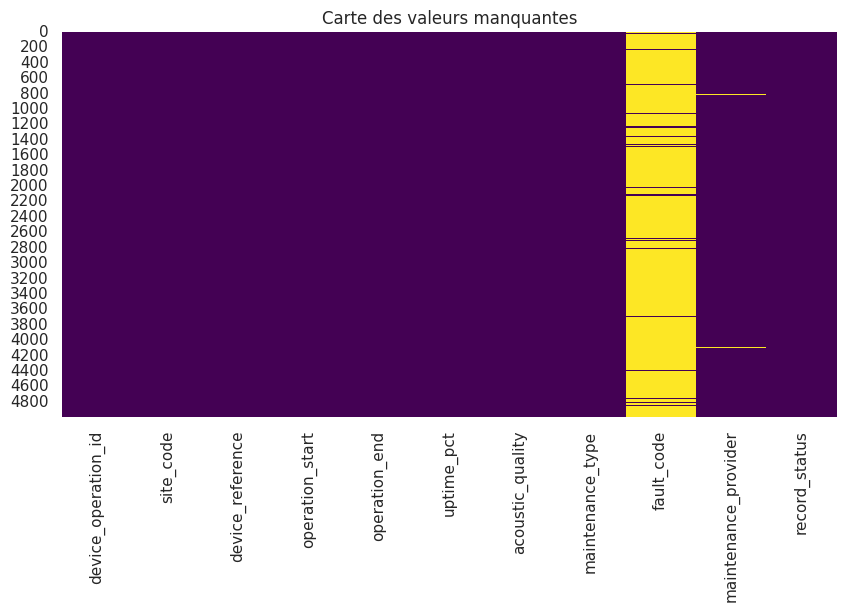

In [8]:
missing = pd.DataFrame({
    "Valeurs manquantes": ops.isnull().sum(),
    "Pourcentage (%)": ops.isnull().mean() * 100
})

missing = missing.sort_values(
    "Pourcentage (%)",
    ascending=False
)

display(missing)

plt.figure(figsize=(10, 5))

sns.heatmap(
    ops.isnull(),
    cbar=False,
    cmap="viridis"
)

plt.title("Carte des valeurs manquantes")
plt.show()

Recherche des doublons

In [9]:
print("Doublons complets :", ops.duplicated().sum())

print(
    "Identifiants d'opérations dupliqués :",
    ops["device_operation_id"].duplicated().sum()
)

print("\nLignes concernées :")

display(
    ops[
        ops["device_operation_id"].duplicated(keep=False)
    ].sort_values("device_operation_id")
)

Doublons complets : 2
Identifiants d'opérations dupliqués : 2

Lignes concernées :


,device_operation_id,site_code,device_reference,operation_start,operation_end,uptime_pct,acoustic_quality,maintenance_type,fault_code,maintenance_provider,record_status
1225,DOP-0001226,KNT-CHP,DEV-KNTCHP-3,2023-08-01T00:00:00,2023-08-31T23:59:59,93.2,73.5,routine inspection,NaN,ECO-SERVICE-1,closed
4993,DOP-0001226,KNT-CHP,DEV-KNTCHP-3,2023-08-01T00:00:00,2023-08-31T23:59:59,93.2,73.5,routine inspection,NaN,ECO-SERVICE-1,closed
1390,DOP-0001391,KNT-WUQ,DEV-KNTWUQ-2,2024-05-01T00:00:00,2024-05-31T23:59:59,92.7,78.6,routine inspection,NaN,ECO-SERVICE-3,closed
4992,DOP-0001391,KNT-WUQ,DEV-KNTWUQ-2,2024-05-01T00:00:00,2024-05-31T23:59:59,92.7,78.6,routine inspection,NaN,ECO-SERVICE-3,closed


Vérification des valeurs et incohérences

In [10]:
print("Types de maintenance :")
print(ops["maintenance_type"].value_counts(dropna=False))

print("\nCodes de panne :")
print(ops["fault_code"].value_counts(dropna=False))

print("\nPrestataires :")
print(ops["maintenance_provider"].value_counts(dropna=False))

print("\nÉtats des enregistrements :")
print(ops["record_status"].value_counts(dropna=False))

print("\nValeurs de uptime non numériques :")

uptime_test = pd.to_numeric(
    ops["uptime_pct"].astype(str)
    .str.strip()
    .str.replace("%", "", regex=False)
    .str.replace(",", ".", regex=False),
    errors="coerce"
)

display(
    ops.loc[
        uptime_test.isna(),
        ["device_operation_id", "uptime_pct"]
    ].head(20)
)

Types de maintenance :
maintenance_type
routine inspection        4785
corrective maintenance     137
sensor replacement          52
ROUTINE INSPECTION          12
Routine Inspection           8
Name: count, dtype: int64

Codes de panne :
fault_code
NaN                   4805
MICROPHONE_DRIFT        97
STORAGE_LIMIT           56
POWER_INTERRUPTION      36
Name: count, dtype: int64

Prestataires :
maintenance_provider
ECO-SERVICE-2    1242
ECO-SERVICE-1    1242
ECO-SERVICE-3    1240
ECO-SERVICE-4    1240
NaN                30
Name: count, dtype: int64

États des enregistrements :
record_status
closed    4974
CLOSED      13
Closed       7
Name: count, dtype: int64

Valeurs de uptime non numériques :


,device_operation_id,uptime_pct


Analyse des dates

In [11]:
dates_debut = pd.to_datetime(
    ops["operation_start"],
    errors="coerce"
)

dates_fin = pd.to_datetime(
    ops["operation_end"],
    errors="coerce"
)

print("Date de début la plus ancienne :", dates_debut.min())
print("Date de début la plus récente :", dates_debut.max())

print("\nDates de début manquantes :", dates_debut.isna().sum())
print("Dates de fin manquantes :", dates_fin.isna().sum())

print(
    "\nDates de fin antérieures aux dates de début :",
    (dates_fin < dates_debut).sum()
)

Date de début la plus ancienne : 2019-01-01 00:00:00
Date de début la plus récente : 2025-06-01 00:00:00

Dates de début manquantes : 0
Dates de fin manquantes : 20

Dates de fin antérieures aux dates de début : 0


Nettoyage

In [12]:
operations = ops.copy()

# 1. Suppression des doublons exacts
operations = operations.drop_duplicates()

# 2. Normalisation des variables catégorielles
colonnes_texte = [
    "site_code",
    "device_reference",
    "maintenance_type",
    "fault_code",
    "maintenance_provider",
    "record_status"
]

for col in colonnes_texte:
    operations[col] = (
        operations[col]
        .astype("string")
        .str.strip()
        .str.lower()
    )

# 3. Conversion de uptime_pct
operations["uptime_pct"] = pd.to_numeric(
    operations["uptime_pct"]
    .astype("string")
    .str.replace("%", "", regex=False)
    .str.replace(",", ".", regex=False),
    errors="coerce"
)

# 4. Conversion des dates
operations["operation_start"] = pd.to_datetime(
    operations["operation_start"],
    errors="coerce"
)

operations["operation_end"] = pd.to_datetime(
    operations["operation_end"],
    errors="coerce"
)

# 5. Création d'une variable indiquant les valeurs initialement manquantes
operations["uptime_missing"] = operations["uptime_pct"].isna()

operations["end_date_missing"] = operations["operation_end"].isna()

# 6. Traitement des valeurs manquantes de uptime
mediane_uptime = operations["uptime_pct"].median()

operations["uptime_pct"] = (
    operations["uptime_pct"].fillna(mediane_uptime)
)

# 7. Création d'une variable indiquant la présence d'une panne
operations["has_fault"] = operations["fault_code"].notna()

print("Dimensions après nettoyage :", operations.shape)

print("\nValeurs manquantes restantes :")
display(
    operations.isnull().sum().to_frame("Valeurs manquantes")
)

Dimensions après nettoyage : (4992, 14)

Valeurs manquantes restantes :


,Valeurs manquantes
device_operation_id,0
site_code,0
device_reference,0
operation_start,0
operation_end,20
uptime_pct,0
acoustic_quality,0
maintenance_type,0
fault_code,4803
maintenance_provider,30


Analyse statistique et corrélations

In [13]:
variables_num = [
    "uptime_pct",
    "acoustic_quality"
]

display(operations[variables_num].describe())

,uptime_pct,acoustic_quality
count,4992.0,4992.000000
mean,92.525962,78.992448
std,7.926554,8.506378
min,23.1,20.000000
25%,90.2,73.900000
50%,93.8,79.300000
75%,97.3,84.625000
max,100.0,100.000000


Corrélation entre disponibilité et qualité acoustique

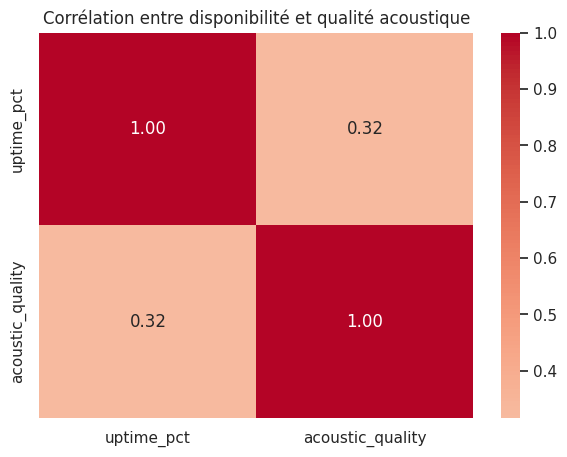

In [14]:
corr = operations[variables_num].corr(method="pearson")

plt.figure(figsize=(7, 5))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)

plt.title("Corrélation entre disponibilité et qualité acoustique")
plt.show()

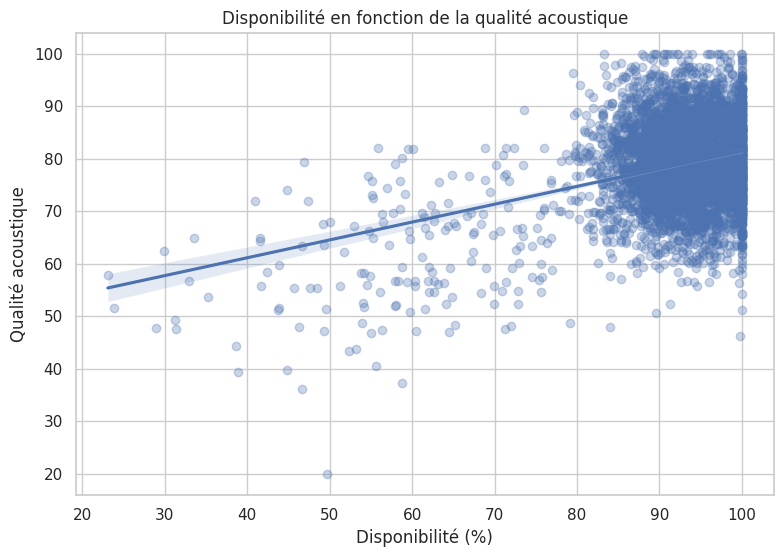

In [15]:
plt.figure(figsize=(9, 6))

sns.regplot(
    data=operations,
    x="uptime_pct",
    y="acoustic_quality",
    scatter_kws={"alpha": 0.3}
)

plt.title("Disponibilité en fonction de la qualité acoustique")
plt.xlabel("Disponibilité (%)")
plt.ylabel("Qualité acoustique")
plt.show()

In [16]:
r, p = spearmanr(
    operations["uptime_pct"],
    operations["acoustic_quality"]
)

print("Coefficient de Spearman :", round(r, 4))
print("P-value :", round(p, 5))

if p < 0.05:
    print("Une relation monotone statistiquement significative est observée.")
else:
    print("Aucune relation monotone significative n'est mise en évidence.")

Coefficient de Spearman : 0.0838
P-value : 0.0
Une relation monotone statistiquement significative est observée.


Relations entre les variables catégorielles

In [17]:
relations = [
    ("maintenance_type", "fault_code"),
    ("maintenance_provider", "fault_code"),
    ("maintenance_type", "record_status"),
    ("site_code", "maintenance_type")
]

for col1, col2 in relations:

    tableau = pd.crosstab(
        operations[col1],
        operations[col2]
    )

    print(f"\nRelation entre {col1} et {col2}")

    display(tableau)

    if tableau.shape[0] > 1 and tableau.shape[1] > 1:

        chi2, p, ddl, expected = chi2_contingency(tableau)

        print("Chi-deux :", round(chi2, 3))
        print("P-value :", round(p, 5))
        print("Effectif théorique minimum :", round(expected.min(), 2))


Relation entre maintenance_type et fault_code


fault_code,microphone_drift,power_interruption,storage_limit
maintenance_type,,,
corrective maintenance,45,36,56
sensor replacement,52,0,0


Chi-deux : 68.039
P-value : 0.0
Effectif théorique minimum : 9.9

Relation entre maintenance_provider et fault_code


fault_code,microphone_drift,power_interruption,storage_limit
maintenance_provider,,,
eco-service-1,59,7,13
eco-service-2,11,9,13
eco-service-3,14,11,18
eco-service-4,12,9,12


Chi-deux : 30.833
P-value : 3e-05
Effectif théorique minimum : 6.32

Relation entre maintenance_type et record_status


record_status,closed
maintenance_type,
corrective maintenance,137
routine inspection,4803
sensor replacement,52



Relation entre site_code et maintenance_type


maintenance_type,corrective maintenance,routine inspection,sensor replacement
site_code,,,
avl-abg,3,75,0
avl-aru,2,76,0
avl-bvm,0,78,0
avl-bwk,0,78,0
avl-der,1,77,0
...,...,...,...
tmb-vzt,3,75,0
tmb-wql,4,74,0
tmb-wst,3,75,0


Chi-deux : 1667.836
P-value : 0.0
Effectif théorique minimum : 0.81


Analyse temporelle

In [18]:
operations["operation_year"] = (
    operations["operation_start"].dt.year
)

operations["operation_month"] = (
    operations["operation_start"].dt.month
)

operations["operation_period"] = (
    operations["operation_start"].dt.to_period("M")
)

operations["operation_duration_days"] = (
    operations["operation_end"] -
    operations["operation_start"]
).dt.total_seconds() / 86400

display(
    operations[
        [
            "operation_start",
            "operation_end",
            "operation_duration_days",
            "operation_year",
            "operation_month"
        ]
    ].head()
)

,operation_start,operation_end,operation_duration_days,operation_year,operation_month
0,2019-01-01,2019-01-31 23:59:59,30.999988,2019,1
1,2019-02-01,2019-02-28 23:59:59,27.999988,2019,2
2,2019-03-01,2019-03-31 23:59:59,30.999988,2019,3
3,2019-04-01,2019-04-30 23:59:59,29.999988,2019,4
4,2019-05-01,2019-05-31 23:59:59,30.999988,2019,5


Nombre d'opérations par année

,Nombre d'opérations
operation_year,
2019,768
2020,768
2021,768
2022,768
2023,768
2024,768
2025,384


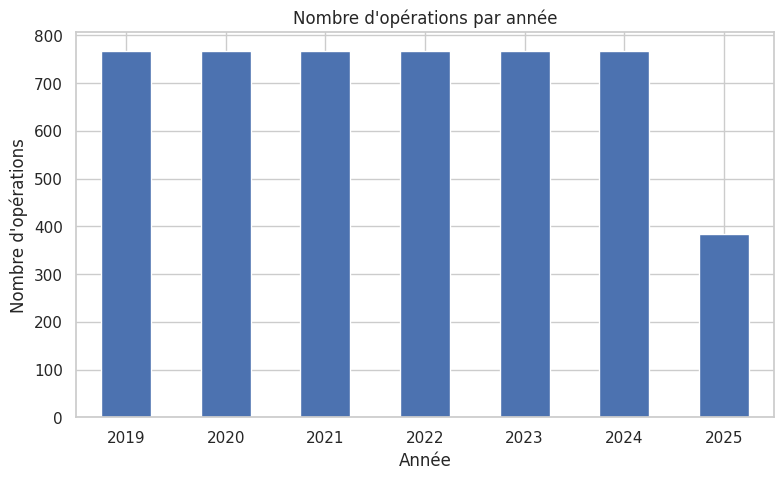

In [19]:
operations_per_year = (
    operations.groupby("operation_year")
    .size()
)

display(operations_per_year.to_frame("Nombre d'opérations"))

operations_per_year.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Nombre d'opérations par année")
plt.xlabel("Année")
plt.ylabel("Nombre d'opérations")
plt.xticks(rotation=0)
plt.show()

Évolution mensuelle de la disponibilité

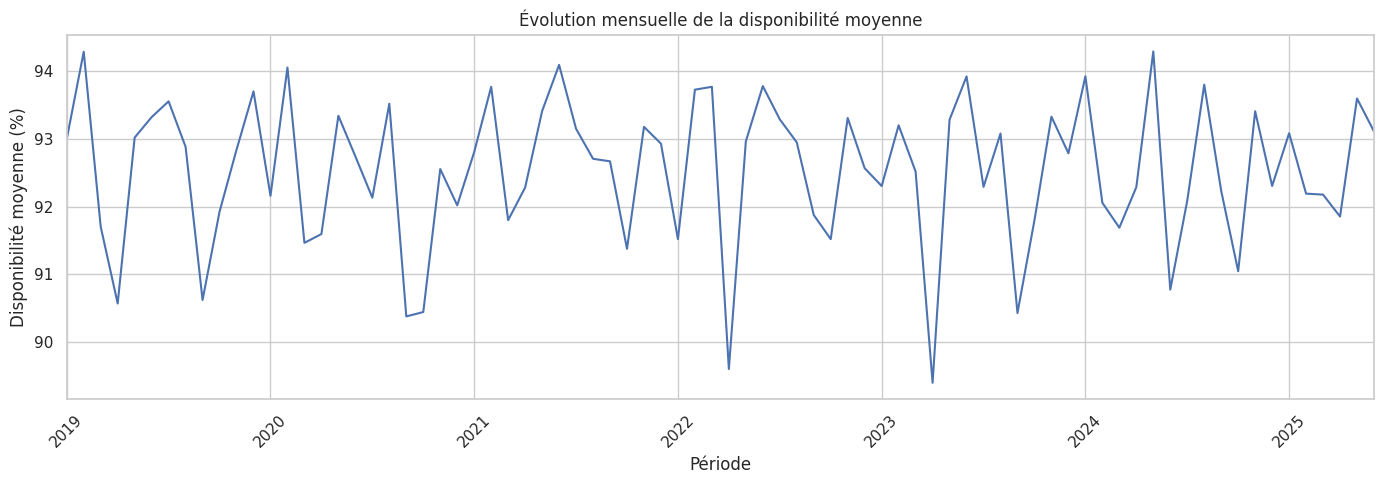

In [20]:
monthly_uptime = (
    operations.groupby("operation_period")["uptime_pct"]
    .mean()
)

plt.figure(figsize=(14, 5))

monthly_uptime.plot()

plt.title("Évolution mensuelle de la disponibilité moyenne")
plt.xlabel("Période")
plt.ylabel("Disponibilité moyenne (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Évolution mensuelle de la qualité acoustique

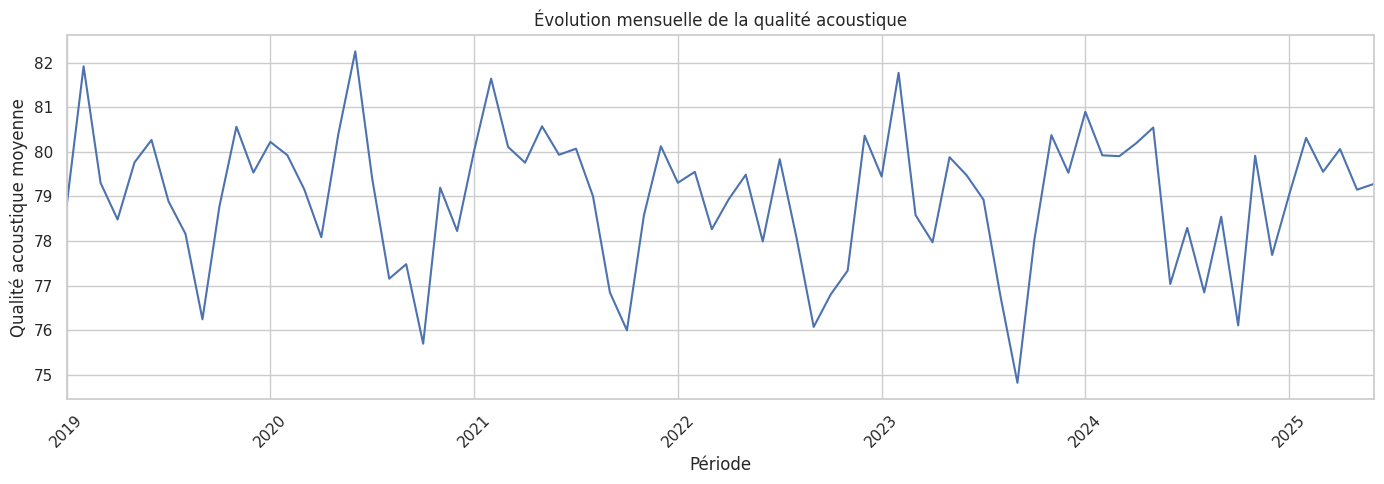

In [21]:
monthly_acoustic = (
    operations.groupby("operation_period")["acoustic_quality"]
    .mean()
)

plt.figure(figsize=(14, 5))

monthly_acoustic.plot()

plt.title("Évolution mensuelle de la qualité acoustique")
plt.xlabel("Période")
plt.ylabel("Qualité acoustique moyenne")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Analyse des pannes dans le temps

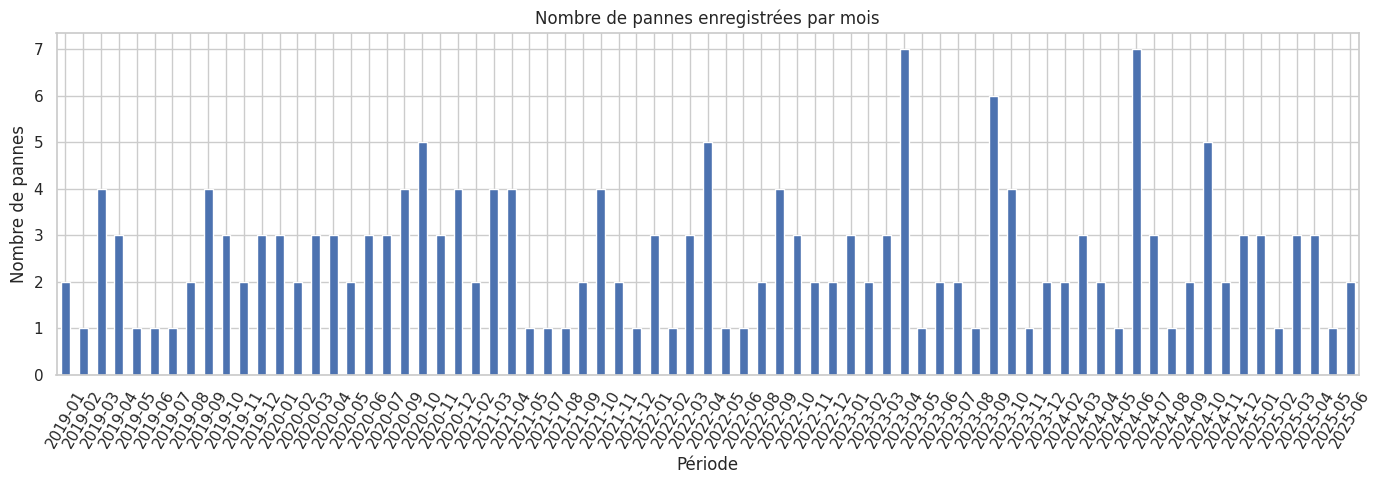

In [22]:
faults_by_month = (
    operations[operations["has_fault"]]
    .groupby("operation_period")
    .size()
)

plt.figure(figsize=(14, 5))

faults_by_month.plot(kind="bar")

plt.title("Nombre de pannes enregistrées par mois")
plt.xlabel("Période")
plt.ylabel("Nombre de pannes")
plt.xticks(rotation=60)
plt.tight_layout()
plt.show()

Analyse des types de pannes

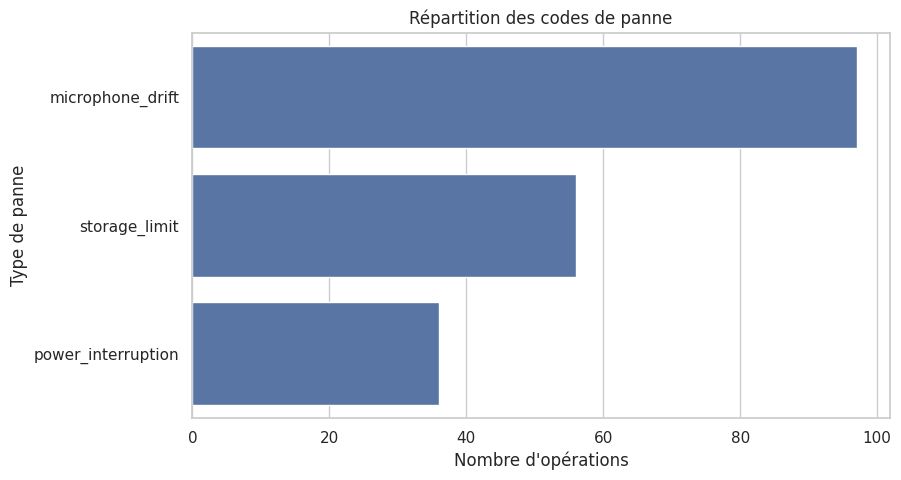

In [23]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=operations[operations["has_fault"]],
    y="fault_code",
    order=operations["fault_code"].value_counts().index
)

plt.title("Répartition des codes de panne")
plt.xlabel("Nombre d'opérations")
plt.ylabel("Type de panne")
plt.show()

Analyse des comportements des appareils

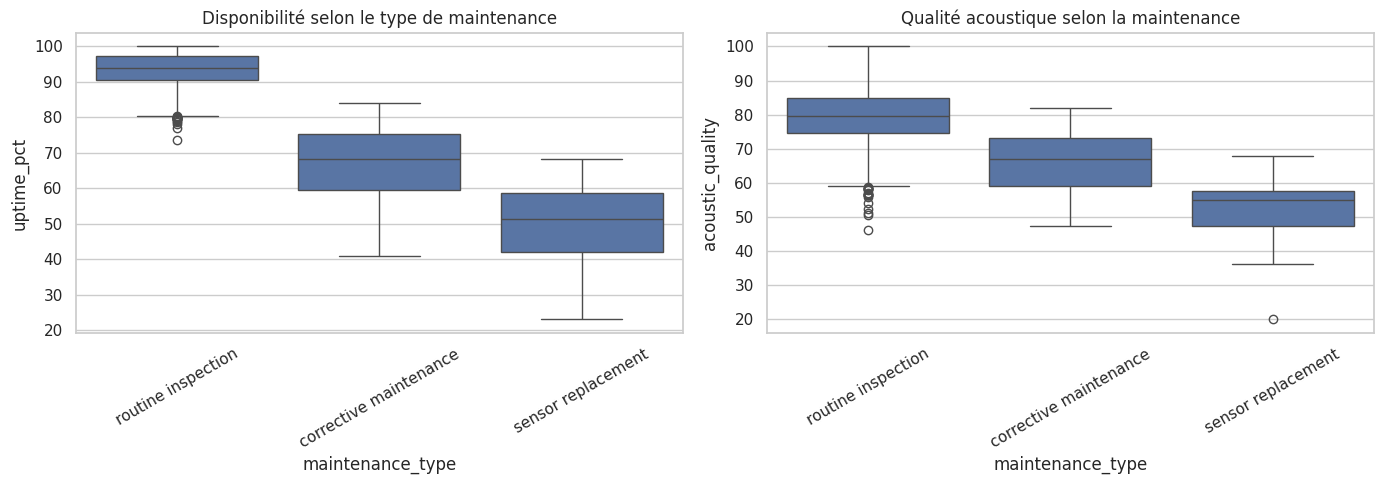

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(
    data=operations,
    x="maintenance_type",
    y="uptime_pct",
    ax=axes[0]
)

axes[0].set_title("Disponibilité selon le type de maintenance")
axes[0].tick_params(axis="x", rotation=30)

sns.boxplot(
    data=operations,
    x="maintenance_type",
    y="acoustic_quality",
    ax=axes[1]
)

axes[1].set_title("Qualité acoustique selon la maintenance")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

Comparaison des opérations avec et sans panne

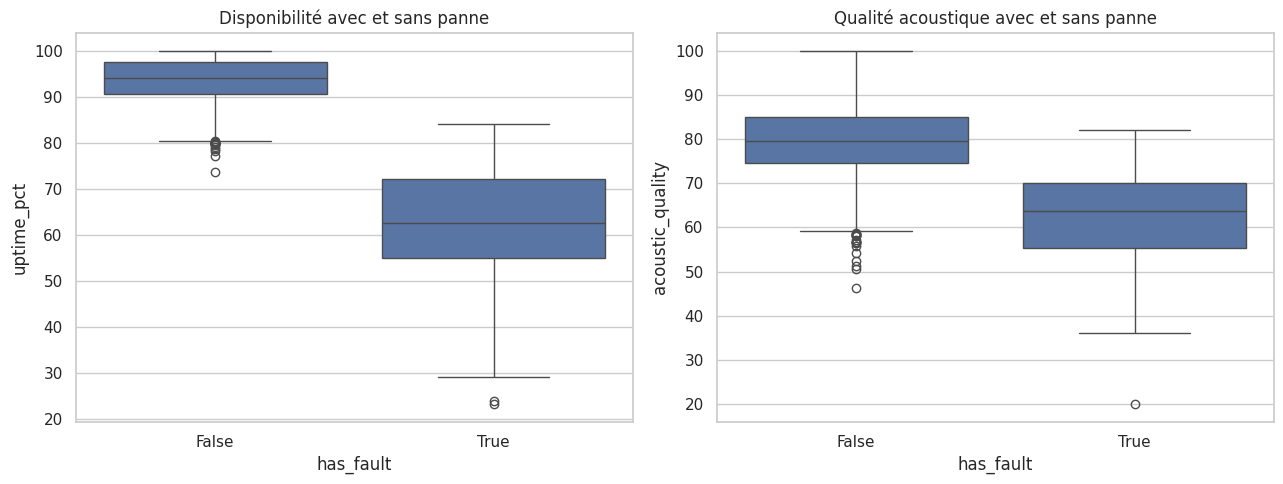

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.boxplot(
    data=operations,
    x="has_fault",
    y="uptime_pct",
    ax=axes[0]
)

axes[0].set_title("Disponibilité avec et sans panne")

sns.boxplot(
    data=operations,
    x="has_fault",
    y="acoustic_quality",
    ax=axes[1]
)

axes[1].set_title("Qualité acoustique avec et sans panne")

plt.tight_layout()
plt.show()

Analyse par prestataire

In [26]:
prestataires = (
    operations.groupby("maintenance_provider")
    .agg(
        nombre_operations=("device_operation_id", "count"),
        disponibilite_moyenne=("uptime_pct", "mean"),
        qualite_moyenne=("acoustic_quality", "mean"),
        nombre_pannes=("has_fault", "sum")
    )
    .sort_values("nombre_pannes", ascending=False)
)

display(prestataires)

,nombre_operations,disponibilite_moyenne,qualite_moyenne,nombre_pannes
maintenance_provider,,,,
eco-service-1,1241,91.193715,78.098711,79
eco-service-3,1239,92.800404,78.951332,43
eco-service-2,1242,93.235749,79.728180,33
eco-service-4,1240,92.879516,79.218952,33


Clustering

In [27]:
features_cluster = operations[
    ["uptime_pct", "acoustic_quality"]
].copy()

scaler = StandardScaler()

X_scaled = scaler.fit_transform(features_cluster)

print("Dimensions :", X_scaled.shape)

Dimensions : (4992, 2)


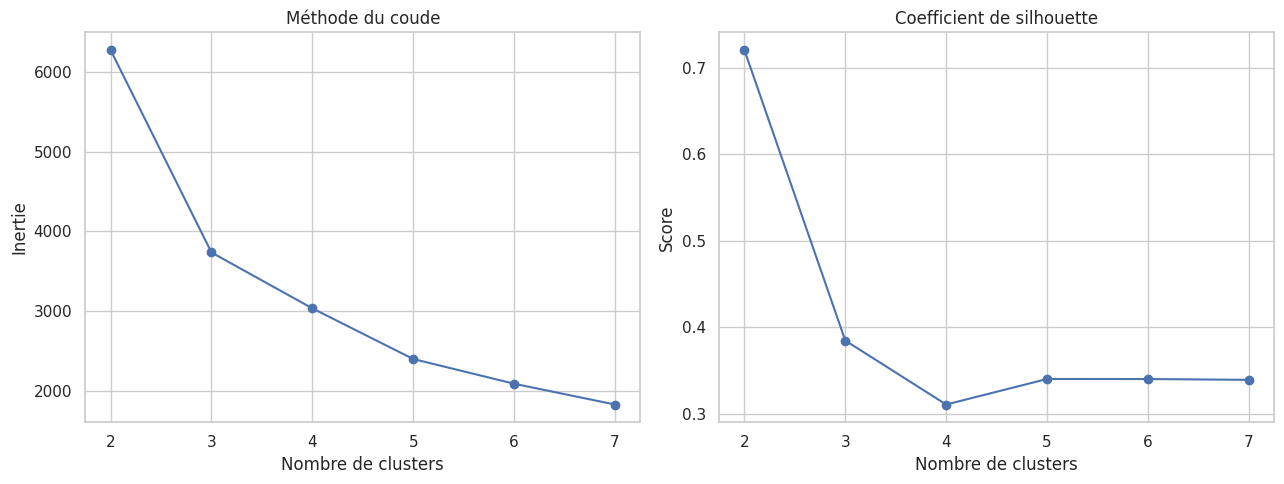

In [28]:
inerties = []
silhouettes = []

valeurs_k = range(2, 8)

for k in valeurs_k:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    inerties.append(model.inertia_)

    silhouettes.append(
        silhouette_score(X_scaled, labels)
    )

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(valeurs_k, inerties, marker="o")
axes[0].set_title("Méthode du coude")
axes[0].set_xlabel("Nombre de clusters")
axes[0].set_ylabel("Inertie")

axes[1].plot(valeurs_k, silhouettes, marker="o")
axes[1].set_title("Coefficient de silhouette")
axes[1].set_xlabel("Nombre de clusters")
axes[1].set_ylabel("Score")

plt.tight_layout()
plt.show()

kmeans

In [29]:
k_optimal = 3  # À adapter selon les résultats

kmeans = KMeans(
    n_clusters=k_optimal,
    random_state=42,
    n_init=10
)

operations["cluster"] = kmeans.fit_predict(X_scaled)

print("Répartition des clusters :")

display(
    operations["cluster"].value_counts().sort_index()
)

print("\nCaractéristiques moyennes :")

display(
    operations.groupby("cluster")[
        ["uptime_pct", "acoustic_quality"]
    ].mean()
)

Répartition des clusters :


,count
cluster,
0,2431
1,2399
2,162



Caractéristiques moyennes :


,uptime_pct,acoustic_quality
cluster,,
0,93.659153,85.723941
1,93.629721,73.377741
2,59.175926,61.124691


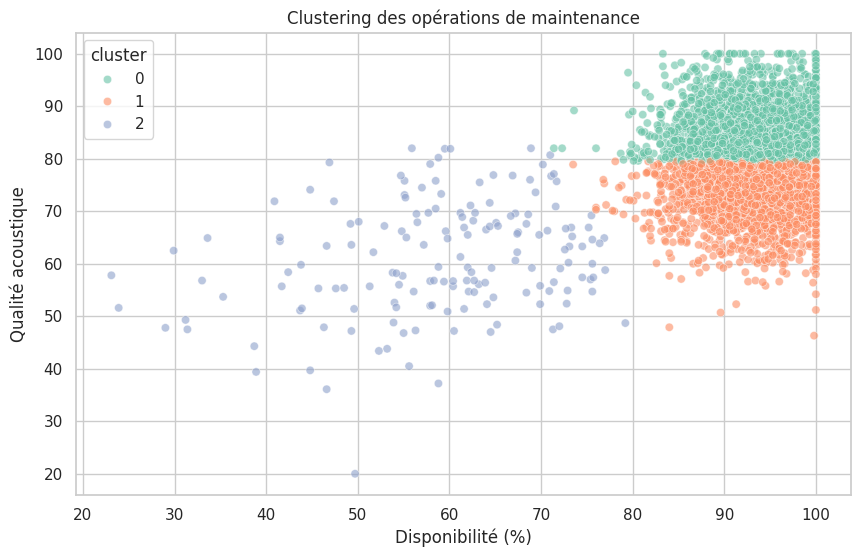

In [30]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=operations,
    x="uptime_pct",
    y="acoustic_quality",
    hue="cluster",
    palette="Set2",
    alpha=0.6
)

plt.title("Clustering des opérations de maintenance")
plt.xlabel("Disponibilité (%)")
plt.ylabel("Qualité acoustique")
plt.show()

DBSCAN

In [31]:
dbscan = DBSCAN(
    eps=0.5,
    min_samples=10
)

operations["dbscan_cluster"] = dbscan.fit_predict(X_scaled)

print("Répartition DBSCAN :")

display(
    operations["dbscan_cluster"].value_counts()
)

print(
    "Nombre d'opérations considérées comme bruit :",
    (operations["dbscan_cluster"] == -1).sum()
)

Répartition DBSCAN :


,count
dbscan_cluster,
0,4879
-1,76
1,28
2,9


Nombre d'opérations considérées comme bruit : 76


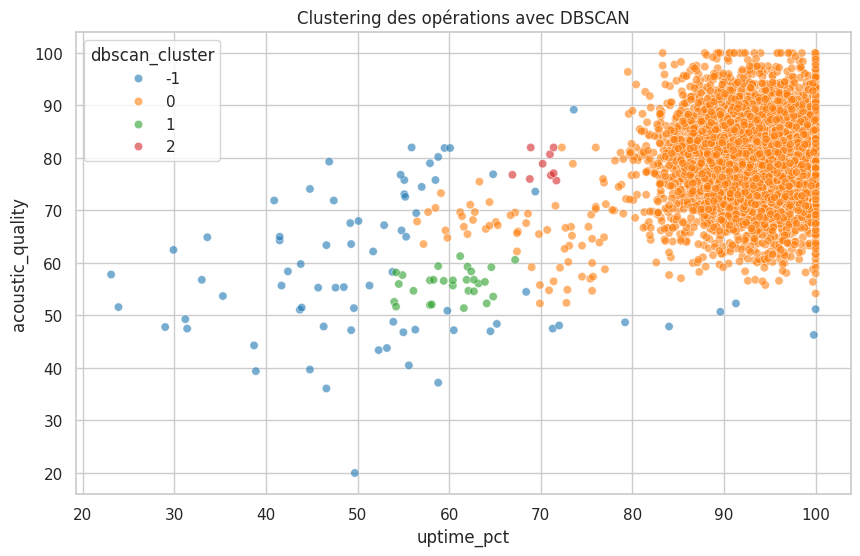

In [32]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=operations,
    x="uptime_pct",
    y="acoustic_quality",
    hue="dbscan_cluster",
    palette="tab10",
    alpha=0.6
)

plt.title("Clustering des opérations avec DBSCAN")
plt.show()

Détection des anomalies

In [33]:
features_anomalies = operations[
    ["uptime_pct", "acoustic_quality"]
].copy()

scaler_anomaly = StandardScaler()

X_anomaly = scaler_anomaly.fit_transform(
    features_anomalies
)

ISOLATION FOREST

In [34]:
iso = IsolationForest(
    contamination=0.03,
    random_state=42
)

operations["anomaly_if"] = iso.fit_predict(X_anomaly)

operations["anomaly_if"] = operations["anomaly_if"].map({
    1: "Normal",
    -1: "Anomalie"
})

print("Résultats Isolation Forest :")

display(
    operations["anomaly_if"].value_counts()
)

print("\nOpérations identifiées comme anomalies :")

display(
    operations[
        operations["anomaly_if"] == "Anomalie"
    ][
        [
            "device_operation_id",
            "site_code",
            "uptime_pct",
            "acoustic_quality",
            "maintenance_type",
            "fault_code"
        ]
    ].head(30)
)

Résultats Isolation Forest :


,count
anomaly_if,
Normal,4842
Anomalie,150



Opérations identifiées comme anomalies :


,device_operation_id,site_code,uptime_pct,acoustic_quality,maintenance_type,fault_code
11,DOP-0000012,knt-kes,69.9,52.3,corrective maintenance,storage_limit
20,DOP-0000021,knt-kes,52.9,67.2,corrective maintenance,microphone_drift
91,DOP-0000092,knt-lum,77.0,58.8,corrective maintenance,power_interruption
101,DOP-0000102,knt-lum,62.6,68.2,corrective maintenance,microphone_drift
104,DOP-0000105,knt-lum,63.2,56.1,corrective maintenance,microphone_drift
151,DOP-0000152,knt-lum,40.9,71.9,corrective maintenance,storage_limit
156,DOP-0000157,knt-sen,47.4,71.9,corrective maintenance,microphone_drift
202,DOP-0000203,knt-sen,61.6,66.9,corrective maintenance,storage_limit
227,DOP-0000228,knt-sen,67.2,60.6,corrective maintenance,microphone_drift
246,DOP-0000247,avl-mar,57.7,69.7,corrective maintenance,power_interruption


LOF

In [35]:
lof = LocalOutlierFactor(
    n_neighbors=20,
    contamination=0.03
)

lof_labels = lof.fit_predict(X_anomaly)

operations["anomaly_lof"] = np.where(
    lof_labels == -1,
    "Anomalie",
    "Normal"
)

print("Résultats LOF :")

display(
    operations["anomaly_lof"].value_counts()
)

print("\nComparaison des deux méthodes :")

display(
    pd.crosstab(
        operations["anomaly_if"],
        operations["anomaly_lof"]
    )
)

Résultats LOF :


,count
anomaly_lof,
Normal,4842
Anomalie,150



Comparaison des deux méthodes :


anomaly_lof,Anomalie,Normal
anomaly_if,,
Anomalie,34,116
Normal,116,4726


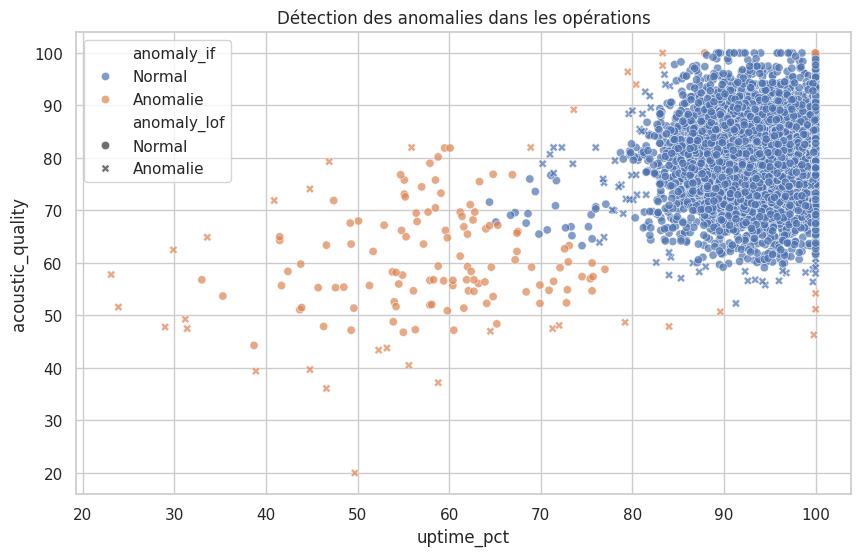

In [36]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=operations,
    x="uptime_pct",
    y="acoustic_quality",
    hue="anomaly_if",
    style="anomaly_lof",
    alpha=0.7
)

plt.title("Détection des anomalies dans les opérations")
plt.show()

Graph Mining

In [37]:
G = nx.Graph()

operations_graphe = operations.dropna(
    subset=["site_code", "maintenance_provider"]
)

relations = (
    operations_graphe.groupby(
        ["site_code", "maintenance_provider"]
    )
    .size()
    .reset_index(name="nombre_operations")
)

# Création des nœuds
for site in relations["site_code"].unique():

    G.add_node(
        "SITE_" + site,
        type="site"
    )

for provider in relations["maintenance_provider"].unique():

    G.add_node(
        "PROVIDER_" + provider,
        type="prestataire"
    )

# Création des relations pondérées
for _, row in relations.iterrows():

    G.add_edge(
        "SITE_" + row["site_code"],
        "PROVIDER_" + row["maintenance_provider"],
        weight=row["nombre_operations"]
    )

print("Nombre de nœuds :", G.number_of_nodes())
print("Nombre de relations :", G.number_of_edges())

print(
    "Nombre de composantes connexes :",
    nx.number_connected_components(G)
)

Nombre de nœuds : 68
Nombre de relations : 64
Nombre de composantes connexes : 4


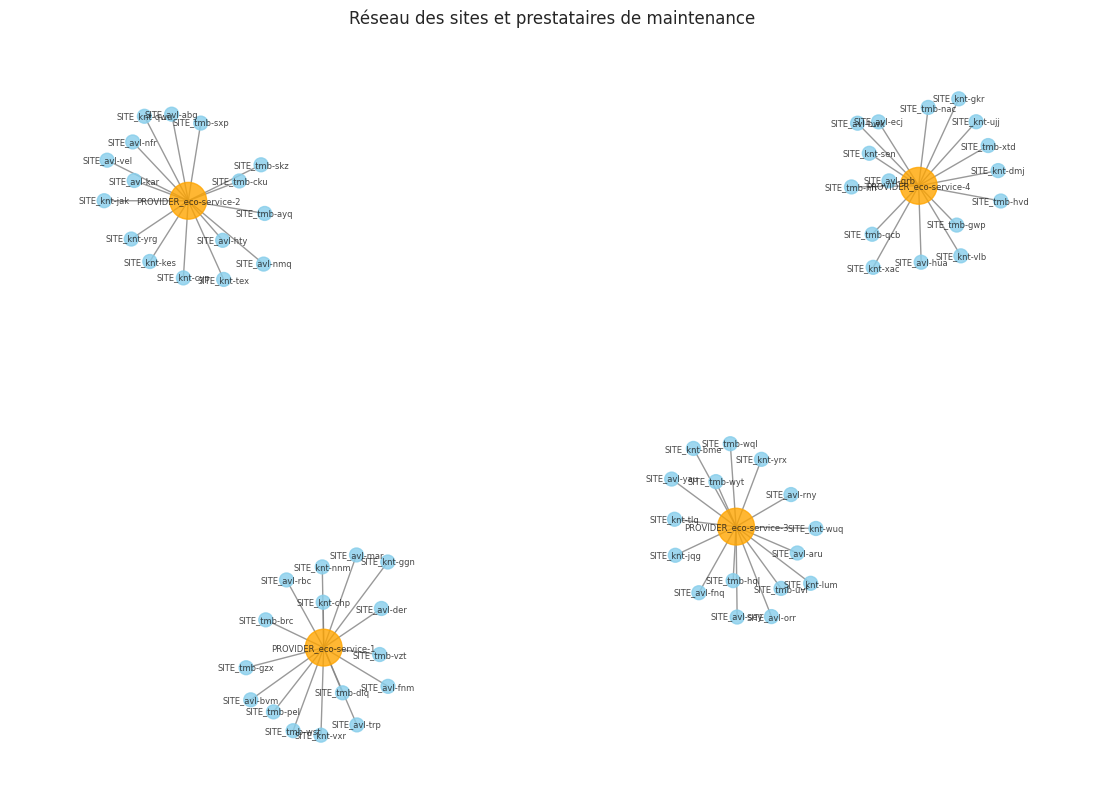

In [38]:
plt.figure(figsize=(14, 10))

pos = nx.spring_layout(
    G,
    seed=42,
    k=0.8
)

couleurs = [
    "skyblue" if G.nodes[n]["type"] == "site"
    else "orange"
    for n in G.nodes()
]

tailles = [
    100 if G.nodes[n]["type"] == "site"
    else 700
    for n in G.nodes()
]

nx.draw_networkx(
    G,
    pos,
    with_labels=True,
    node_color=couleurs,
    node_size=tailles,
    font_size=6,
    edge_color="gray",
    alpha=0.8
)

plt.title("Réseau des sites et prestataires de maintenance")
plt.axis("off")
plt.show()

In [39]:
centrality = pd.DataFrame({
    "entite": list(G.nodes()),
    "degree_centrality": [
        nx.degree_centrality(G)[n]
        for n in G.nodes()
    ],
    "weighted_degree": [
        G.degree(n, weight="weight")
        for n in G.nodes()
    ]
})

print("Entités les plus connectées :")

display(
    centrality.sort_values(
        "weighted_degree",
        ascending=False
    ).head(15)
)

Entités les plus connectées :


,entite,degree_centrality,weighted_degree
64,PROVIDER_eco-service-2,0.238806,1242
66,PROVIDER_eco-service-1,0.238806,1241
67,PROVIDER_eco-service-4,0.238806,1240
65,PROVIDER_eco-service-3,0.238806,1239
62,SITE_tmb-wyt,0.014925,78
2,SITE_avl-bvm,0.014925,78
1,SITE_avl-aru,0.014925,78
0,SITE_avl-abg,0.014925,78
4,SITE_avl-der,0.014925,78
5,SITE_avl-ecj,0.014925,78


Mining Text and Other Unstructured Data

,Code de panne,Fréquence
0,microphone_drift,97
1,storage_limit,56
2,power_interruption,36


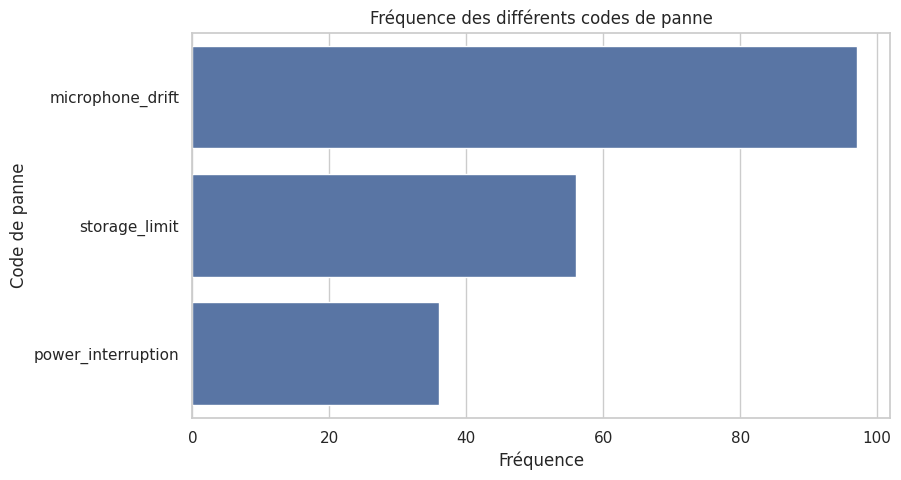

In [40]:
faults = (
    operations["fault_code"]
    .value_counts()
    .reset_index()
)

faults.columns = ["Code de panne", "Fréquence"]

display(faults)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=faults,
    x="Fréquence",
    y="Code de panne"
)

plt.title("Fréquence des différents codes de panne")
plt.show()

Association entre pannes et types de maintenance

fault_code,microphone_drift,power_interruption,storage_limit
maintenance_type,,,
corrective maintenance,45,36,56
sensor replacement,52,0,0


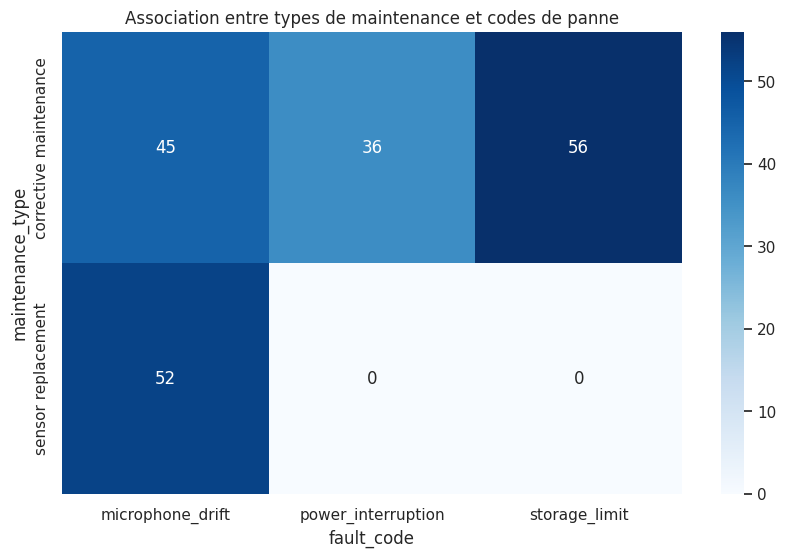

In [41]:
table_fault_maintenance = pd.crosstab(
    operations["maintenance_type"],
    operations["fault_code"]
)

display(table_fault_maintenance)

plt.figure(figsize=(10, 6))

sns.heatmap(
    table_fault_maintenance,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Association entre types de maintenance et codes de panne")
plt.show()

Synthèse et exportation

In [42]:
print("========== SYNTHÈSE DU DATASET ==========")

print("\n1. Nombre d'opérations :", len(operations))

print("\n2. Nombre de sites :",
      operations["site_code"].nunique())

print("\n3. Nombre d'appareils :",
      operations["device_reference"].nunique())

print("\n4. Répartition des types de maintenance :")
display(operations["maintenance_type"].value_counts())

print("\n5. Répartition des codes de panne :")
display(operations["fault_code"].value_counts())

print("\n6. Disponibilité moyenne :",
      round(operations["uptime_pct"].mean(), 2), "%")

print("\n7. Qualité acoustique moyenne :",
      round(operations["acoustic_quality"].mean(), 2))

print("\n8. Répartition des clusters :")
display(operations["cluster"].value_counts())

print("\n9. Anomalies Isolation Forest :")
display(operations["anomaly_if"].value_counts())

print("\n10. Anomalies LOF :")
display(operations["anomaly_lof"].value_counts())

print("\n11. Nombre de pannes enregistrées :",
      operations["has_fault"].sum())

print("\n12. Dates de fin manquantes :",
      operations["end_date_missing"].sum())

========== SYNTHÈSE DU DATASET ==========

1. Nombre d'opérations : 4992

2. Nombre de sites : 64

3. Nombre d'appareils : 64

4. Répartition des types de maintenance :


,count
maintenance_type,
routine inspection,4803
corrective maintenance,137
sensor replacement,52



5. Répartition des codes de panne :


,count
fault_code,
microphone_drift,97
storage_limit,56
power_interruption,36



6. Disponibilité moyenne : 92.53 %

7. Qualité acoustique moyenne : 78.99

8. Répartition des clusters :


,count
cluster,
0,2431
1,2399
2,162



9. Anomalies Isolation Forest :


,count
anomaly_if,
Normal,4842
Anomalie,150



10. Anomalies LOF :


,count
anomaly_lof,
Normal,4842
Anomalie,150



11. Nombre de pannes enregistrées : 189

12. Dates de fin manquantes : 20


In [43]:
operations.to_csv(
    "monitoring_device_operations_analyzed.csv",
    index=False
)

centrality.to_csv(
    "monitoring_device_graph_metrics.csv",
    index=False
)

print("Les résultats ont été sauvegardés.")

Les résultats ont été sauvegardés.
